

The fixed system is $\dot{\boldsymbol{x}}=\operatorname{diag}(-1,-2)\boldsymbol{x}$, $y=[1,1]\boldsymbol{x}$, with $\boldsymbol{x}_0=[1,0.5]^\top$.

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial.legendre import leggauss

T = 5.0                          # time horizon
degree = 4                       # degree of g
g_coeffs = [                    # these are the coefficients of the polynomial
    lambda k, m: 1.0 + k + m,   # this has no effect on observability gramian and the other coefficients are defined in the next lines
    lambda k, m: 1.0 + 1.5*np.sin(2*np.pi*m),
    lambda k, m: 0.5*k+0.5*np.tanh(3*k*m**3),
    lambda k, m: 0.5*m*np.exp(-k**2*m/np.pi),
    lambda k, m: -0.5*m*np.sinh(-m*k/np.pi),
]

assert T > 0 and degree >= 1 and len(g_coeffs) == degree + 1

x0 = np.array([1.0, 0.5])
decay = np.array([1.0, 2.0])
C = np.array([1.0, 1.0])

def q_coefficients(k, m):  #getting the coefficients of q(y(t)) using polynomial convolution
    c = np.array([f(k, m) for f in g_coeffs], dtype=float)
    b = np.polynomial.polynomial.polyder(c)
    return np.convolve(b, b)

print(f'Degree of g: {degree}; degree of q: {2*(degree-1)}')

Degree of g: 4; degree of q: 6


For $g(s;k,m)=\sum_{r=0}^{p}c_r(k,m)s^r$, we use convolution to compute the coefficients of the polynomial $q(s;k,m)=[g'(s;k,m)]^2=\sum_j a_j(k,m)s^j$.

The moments $M_j=\int_0^T y(t)^j\,\psi(t)^\top\psi(t)\,dt$ are computed independently. The Gramian is constructed exactly as $W_{k,m}=\sum_j a_j(k,m)M_j$ (with a  numerical integration error).

In [13]:
def samples(n):
    nodes, weights = leggauss(n)
    t = T * (nodes + 1) / 2
    weights = T * weights / 2
    psi = C * np.exp(-t[:, None] * decay)  # initial-state sensitivity
    y = psi @ x0
    return weights, y, psi

weights, y, psi = samples(360)
moments = np.array([
    (psi.T * (weights * y**j)) @ psi
    for j in range(2*degree - 1)
])

def gramian(k, m):
    return np.tensordot(q_coefficients(k, m), moments, axes=(0, 0))

print(f'Computed {len(moments)} moment matrices, each {moments[0].shape}.')

Computed 7 moment matrices, each (2, 2).


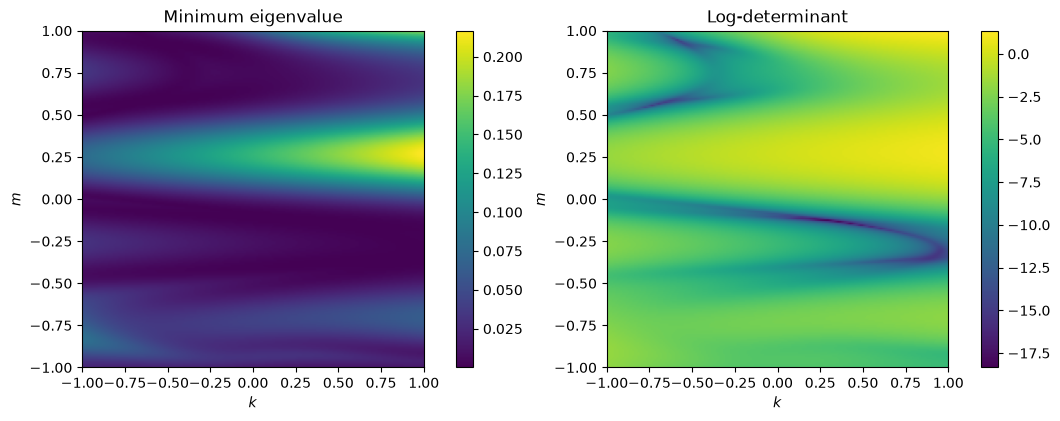

In [14]:
k_values = np.linspace(-1, 1, 200)
m_values = np.linspace(-1, 1, 200)

W = np.array([[gramian(k, m) for k in k_values] for m in m_values])    #construct Gramian using precomputed moments
min_eigenvalue = np.linalg.eigvalsh(W)[..., 0]
sign, logdet = np.linalg.slogdet(W)
logdet = np.where(sign > 0, logdet, np.nan)  

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.1), constrained_layout=True)
for ax, values, title in zip(axes, (min_eigenvalue, logdet),
                             ('Minimum eigenvalue', 'Log-determinant')):
    im = ax.imshow(values, origin='lower', aspect='auto',
                   extent=[k_values[0], k_values[-1], m_values[0], m_values[-1]])
    fig.colorbar(im, ax=ax)
    ax.set(xlabel='$k$', ylabel='$m$', title=title)
plt.show()